In [31]:
import random
import math
import numpy as np
import matplotlib.pyplot as plt
import torch

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

print("torch:", torch.__version__, "| MPS available:", torch.backends.mps.is_available())
random.seed(42); np.random.seed(42); torch.manual_seed(42)

torch: 2.14.0 | MPS available: True


In [32]:
class Value:

    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label
        self._backward = lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward

        return out

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only support int/float" # so use other not other.data
        out = Value(self.data ** other, (self, ), f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward

        return out
        
    def __rmul__(self, other): # fallback other * self
        return self * other 

    def __truediv__(self, other): # self / other
        return self * other**-1

    def __neg__(self): # -self
        return self * -1
    
    def __sub__(self, other): # self - other
        return self + (-other)
    
    def __radd__(self, other): # other + self
        return self + other

    def tanh(self):
        x = self.data
        # t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)  # x 很大时会 OverflowError
        t = math.tanh(x)
        out = Value(t, (self, ), 'tanh')

        def _backward():
            #  d
            # ── tanh(x) = 1 - tanh²(x) = 1 - t²
            # dx
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp') # e^x

        def _backward():
            self.grad += out.data * out.grad # d(e^x) = e^x
        out._backward = _backward

        return out

    def backward(self):

        visited = set()
        topo = []
        def build_topo(node):
            if node not in visited:
                visited.add(node)
                for child in node._prev:
                    build_topo(child)
                topo.append(node)  # 后序：子节点全部处理完才加入自己
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
        

In [33]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

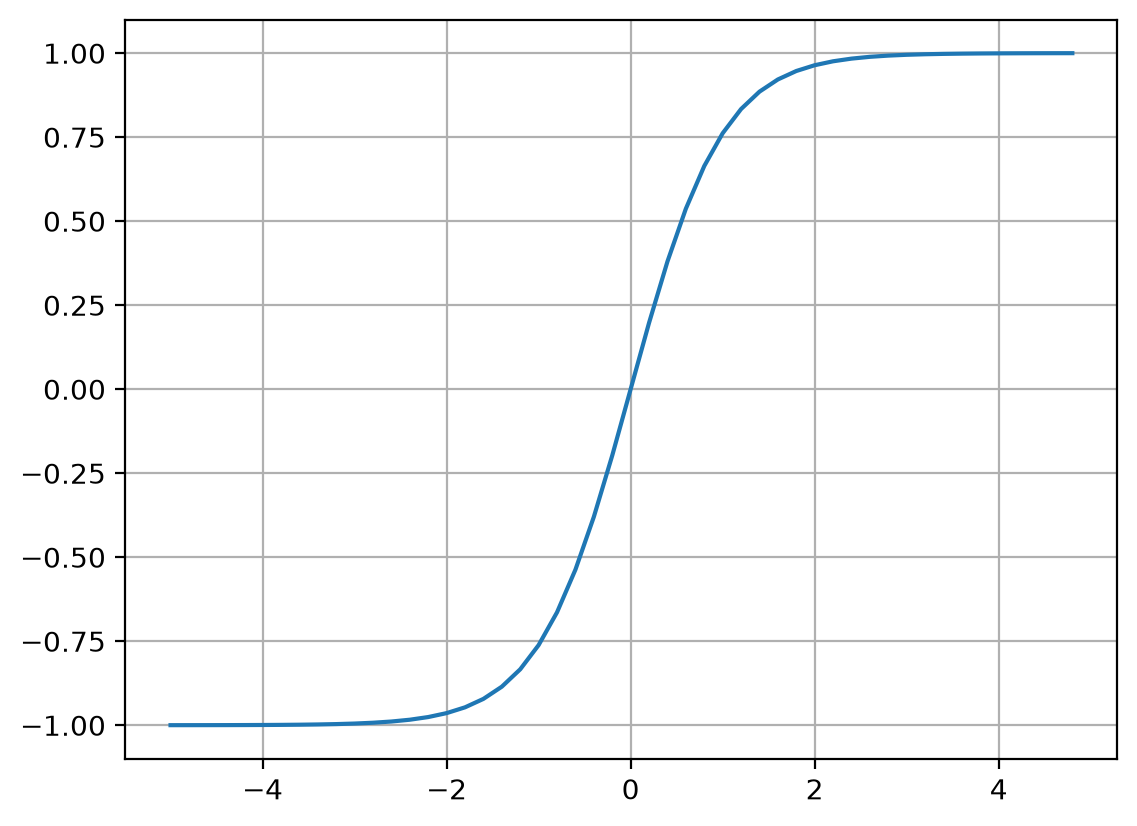

In [8]:
# tanh: active func
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

In [23]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

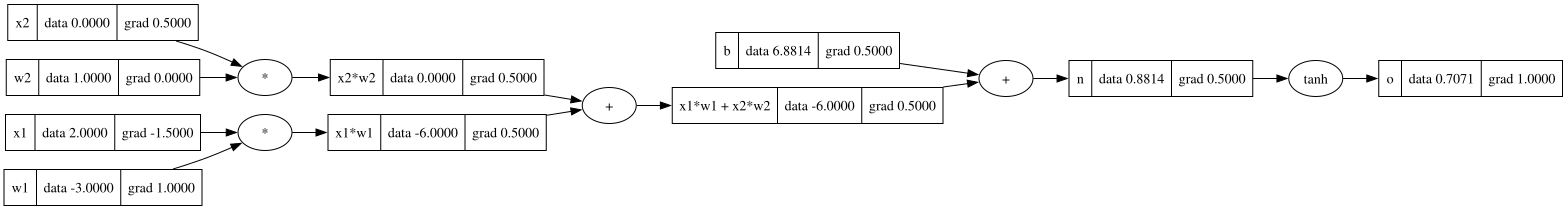

In [26]:
draw_dot(o)

In [11]:
# manual set grad
# o.grad = 1.0
# n.grad = 0.5 # o = n.tanh(); do/dn = 1 - o**2
# b.grad = 0.5
# x1w1x2w2.grad = 0.5
# x1w1.grad = 0.5
# x2w2.grad = 0.5
# x1.grad = -1.5 # w1 * d(x1w1)
# w1.grad = 1.0 # x1 * d(x1w1)
# x2.grad = 0.5 # w2 * d(x2w2)
# w2.grad = 0 # x2 * d(x2w2)

In [16]:
o.grad = 1.0 # init

In [17]:
o._backward()

In [19]:
n._backward()

In [21]:
b._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()

手动链式求导：
 - 每个节点调用_backward时，将 out.grad 传给 self/other

- 向前计算：
c-out = a * b
记录
a.grad = c.grad * b
b.grad = c.grad * a

- 向后更新grad:
call c.backward()


In [ ]:
# 利用拓扑排序自动化计算
o.grad = 1.0

visited = set()
topo = []
def build_topo(node):
    if node not in visited:
        visited.add(node)
        for child in node._prev:
            build_topo(child)
        topo.append(node)  # 后序：子节点全部处理完才加入自己
build_topo(o)
list(reversed(topo))  # backward 按此顺序执行

In [41]:
for node in topo:
    node._backward()

In [25]:
# 更新代码后，调用
o.backward()

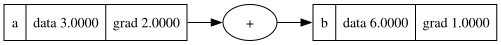

In [20]:
# 累加grad，而不是set
a = Value(3.0, label='a')
b = a + a
b.label = 'b'
b.backward()
draw_dot(b)

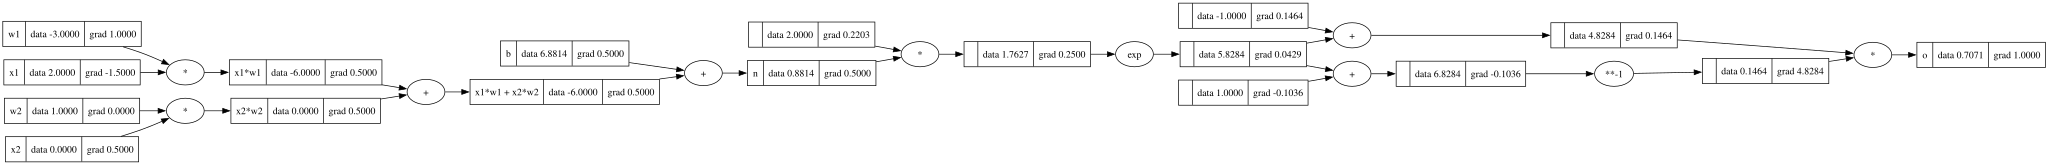

In [34]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# o = n.tanh(); 
e = (2*n).exp()
o = (e - 1) / (e + 1)
o.label = 'o'
o.backward()
draw_dot(o)

In [35]:
import torch

In [37]:
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [59]:
class Neuron:
    def __init__(self, nin): # nin: 输入个数。每个输入配一个权重
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        #  y = tanh(w₁x₁ + w₂x₂ + ⋯ + wₙxₙ + b) = tanh(w · x + b)
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out
        
    def parameters(self):
        return self.w + [self.b]

class Layer: 
  
    def __init__(self, nin, nout):
        # nout 个神经元并排，每个都接收同样的 nin 维输入
        self.neurons = [Neuron(nin) for _ in range(nout)] # 一层（一排神经元） 
    
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]  

class MLP:
  
      def __init__(self, nin, nouts):
        #  - nouts 是各层宽度列表，如 [4, 4, 1]。sz = [3, 4, 4, 1]（拼上输入维度）。                                                                                             
        # - 相邻两两配对建层：Layer(3,4)、Layer(4,4)、Layer(4,1)。   
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
      
      def __call__(self, x):
        for layer in self.layers:
          x = layer(x)
        return x

      def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]


x = [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1])
n(x)

Value(data=0.18963852534076153)

In [60]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

 ```                                                                                                                                                                   
   MLP                                                                                                                                                                 
    └─ layers: [Layer, Layer, Layer]                                                                                                                                   
         └─ 每个 Layer.neurons: [Neuron, Neuron, ...]                                                                                                                  
              └─ 每个 Neuron.w: [Value, Value, Value]   ← 参数在这                                                                                                     
              └─ 每个 Neuron.b: Value                    ← 和这                                                                                                        
 ```      
扁平化：梯度下降根本不关心参数在网络里的位置和结构。清零和更新这两个动作，对第 1 层第 1 个神经元的 w[0] 和最后一层的 b，做法一模一样 .
MLP 内部长什么样（几层、每层几个神经元、以后想不想加 residual）是模型自己的事；训练器只依赖一个约定——"给我一个参数列表"。

In [61]:
n.parameters()

[Value(data=0.719270800507493),
 Value(data=-0.8582853002226931),
 Value(data=-0.5239907312620096),
 Value(data=0.33795555659256116),
 Value(data=-0.5715263852591228),
 Value(data=-0.73537630254995),
 Value(data=0.871028481161342),
 Value(data=0.14208618665056894),
 Value(data=-0.05465794737641172),
 Value(data=0.5692388485815068),
 Value(data=0.6149939955332868),
 Value(data=-0.6191801712762446),
 Value(data=-0.8061383715423533),
 Value(data=-0.13789763518724496),
 Value(data=-0.15284275396015845),
 Value(data=-0.06595066392665005),
 Value(data=0.4581516989197012),
 Value(data=0.34672909458660306),
 Value(data=0.9683304227319323),
 Value(data=-0.8031642576960822),
 Value(data=-0.19475743579546245),
 Value(data=-0.3213947892100737),
 Value(data=0.7233450727055821),
 Value(data=-0.5026873321594287),
 Value(data=-0.619582183118377),
 Value(data=-0.1027729043337362),
 Value(data=-0.15623672033119163),
 Value(data=-0.44290971066611906),
 Value(data=-0.500387104235799),
 Value(data=0.846531

In [66]:
ypred = [n(x) for x in xs]
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=6.461259658735726)

In [67]:
loss.backward()

In [69]:
n.layers[0].neurons[0].w[0].grad  # 得到某个神经元对于loss的梯度，该w能使loss变大, training中我们要减小w

0.6093476136881257

In [70]:
n.layers[0].neurons[0].w[0].data 

0.719270800507493

In [85]:
for k in range(20):
  
  # forward pass
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
  
  # backward pass
  for p in n.parameters():
    p.grad = 0.0 # _backward 全是 grad +=（为了正确处理菱形依赖/共享参数）。如果不清零，第 k 轮的梯度会叠加到第 k-1 轮的残留上，参数会朝错误的方向更新
  loss.backward()
  
  # update
  for p in n.parameters():
    learning_rate = 0.1
    p.data += -learning_rate * p.grad # grad 为正 → 调小；为负 → 调大；绝对值大 → 挪得多
  
  print(k, loss.data)

0 0.0014187204298857043
1 0.0014107853412704196
2 0.0014029361958291585
3 0.0013951716190371956
4 0.0013874902653642138
5 0.0013798908175164165
6 0.0013723719857022475
7 0.0013649325069209255
8 0.0013575711442727813
9 0.0013502866862908527
10 0.0013430779462927733
11 0.0013359437617524016
12 0.0013288829936903717
13 0.0013218945260830093
14 0.0013149772652888874
15 0.0013081301394924489
16 0.0013013520981641083
17 0.0012946421115362949
18 0.0012879991700947913
19 0.001281422284084968


In [86]:
ypred

[Value(data=0.98992807585001),
 Value(data=-0.9811538796532062),
 Value(data=-0.9814454569985837),
 Value(data=0.9780789756196346)]